### Smart‑Building Energy Dataset – Column Schema

| Column          | Type / Unit                                  | Typical Range      | What it Means                                                                                               | Why it Matters for Modelling                                                                                                      |
|-----------------|----------------------------------------------|--------------------|--------------------------------------------------------------------------------------------------------------|------------------------------------------------------------------------------------------------------------------------------------|
| `timestamp`     | **Datetime** (UTC), hourly frequency         | 2015‑01‑01 00:00 → 2016‑12‑31 00:00 (17,521 rows) | Observation time‑stamp, no gaps. | Enables strict time‑aware train/test splits and the creation of lagged or rolling features.                                       |
| `temp_C`        | Float, °C                                    | −3 → 35            | Outdoor air temperature near the building.                                                                  | Primary driver for HVAC mode and load; interacts with hour‑of‑day.                                                                 |
| `humidity_pct`  | Float, % RH                                  | 20 → 100           | Outdoor relative humidity.                                                                                  | Modestly affects energy; moderates perceived temperature and HVAC efficiency.                                                      |
| `occupants`     | Integer, people                              | 0 → ≈ 60           | Synthetic head‑count: ~40 during 08‑18 weekdays, ~5 otherwise, plus noise.                                   | Proxy for lighting/plug loads and comfort requirements.                                                                            |
| `hour_of_day`   | Integer, 0–23                                | 0…23               | Clock hour extracted from `timestamp`.                                                                      | Captures diurnal patterns in occupancy, loads, and solar gains.                                                                    |
| `is_weekend`    | Binary (0 weekday, 1 weekend)                | 0 / 1              | Saturday or Sunday indicator.                                                                               | Combines with `hour_of_day` and `occupants` to describe schedule shifts.                                                            |
| `is_holiday`    | Binary, rare (≈ 3 % of hours)               | 0 / 1              | U.S. federal holiday flag.                                                                                  | Introduces atypical low‑occupancy weekdays.                                                                                        |
| `hvac_mode`     | Categorical: `off`, `heat`, `cool`           | —                  | Heating/cooling/off state: rule‑based on temperature with 10 % random flips.                                 | Creates piece‑wise linear effects and categorical‑continuous interactions.                                                         |
| **`energy_kwh`**| Float, kilowatt‑hours **(dependent variable)**| ≈ 15 → 120         | Hourly electric energy demand: baseline 20 kWh + 0.4 × `occupants` + HVAC load + humidity + holiday + noise. | Target you will predict; linear plus interaction structure makes it ideal for practising linear regression and feature engineering. |

---

### Generative Logic

1. **Weather drivers**  
   *Annual sine wave* sets the broad temperature profile; *diurnal sine* adds hotter afternoons.  
   Humidity follows its own shifted annual sine, so it is correlated with—but not redundant to—temperature.

2. **Schedule drivers**  
   Occupancy spikes only during weekday office hours (08:00 – 18:00).  
   This cascades into higher non‑HVAC loads (lighting, computers).

3. **HVAC mode**  
   Deterministic threshold logic  
   * heat if `temp_C` < 15 °C  
   * cool if `temp_C` > 22 °C  
   plus a 10 % random override, introducing categorical–continuous interactions and realism.

4. **Energy equation**  
   Linear combination of components **+** a piece‑wise linear HVAC term:  

   `energy_kwh = 20 + 0.4·occupants + hvac_load + 0.05·humidity_pct + 3·is_holiday + ε`,  
   with Gaussian noise ε ~ N(0, 3 kWh) to cap the maximum achievable R².

---

### Dependent Variable

* **Name:** `energy_kwh`  
* **Unit:** kilowatt‑hours consumed in the hour (kWh)  
* **Definition:**  
  `20 kWh (baseline) + 0.4 × occupants + hvac_load + 0.05 × humidity_pct + 3 kWh if holiday + noise`  
  where `hvac_load` is proportional to the heating or cooling degree relative to 15 °C or 22 °C.  
* **Role in Assignment:**  
  This is the **regression target**. Your goal is to model and interpret how weather, schedule, and HVAC interactions drive this hourly energy demand.


Below given is the code for generating an example synthetic dataset - you can safely skip that part of code.
Generative logic (so you know where the signal comes from)
Weather drivers
Annual sine wave sets broad temperature profile; diurnal sine adds hotter afternoons. Humidity follows its own shifted annual sine so it is correlated but not redundant.

Schedule drivers
Occupancy spikes only on weekday office hours; this cascades into higher non‑HVAC loads (lighting, computers).

HVAC mode
Deterministic threshold logic (heat < 15 °C, cool > 22 °C) plus 10 % random overrides introduces categorical–continuous interactions and a bit of realistic “mess.”

Energy equation
Linear in each component plus a piece‑wise linear HVAC term. Gaussian noise (3 kWh σ) ensures no model can hit R² = 1, giving you room to compare generalisation.



In [1]:
# =====================================================================
#  SMART‑BUILDING ENERGY — MINI PIPELINE & VISUAL WALK‑THROUGH
# =====================================================================

# -------- 0. Imports & matplotlib style ------------------------------------
import numpy as np
import pandas as pd
pd.set_option('display.expand_frame_repr', False)
import matplotlib.pyplot as plt
plt.style.use("ggplot")      # pleasant colours & grid lines

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

#This is a synthetic dataset and the code below is used to generate it.
#You can skip the code and simply execute it
# -------- 1. Data‑generation function --------------------------------------
def make_smart_building_df(start="2015-01-01", end="2016-12-31", seed=0):
    """
    Synthetic hourly dataset for a single smart building.
    Produces weather, schedule & HVAC info plus electric‑energy target.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, end, freq="h")
    n = len(idx)

    # --- Weather: smooth seasonal + diurnal cycles ------------------------
    year_frac = ((np.arange(n) / 24) % 365) / 365
    temp_C = (
        12 + 13 * np.sin(2 * np.pi * year_frac - 1)   # yearly wave
        + 4  * np.sin(2 * np.pi * idx.hour / 24)      # daily swing
        + rng.normal(0, 2, n)                         # noise
    )
    humidity_pct = np.clip(
        60 + 15 * np.sin(2 * np.pi * year_frac + 1.5) + rng.normal(0, 8, n),
        20, 100
    )

    # --- Calendar & schedule ----------------------------------------------
    is_weekend = (idx.dayofweek >= 5)
    is_holiday = rng.choice([0, 1], size=n, p=[0.97, 0.03])
    hour = idx.hour

    # Occupancy: busy (≈40 people) on weekday 08‑18, sparse (≈5) otherwise
    base_occ = np.where(
        (~is_weekend) & ((hour >= 8) & (hour <= 18)),
        40, 5
    )
    occupants = base_occ + rng.normal(0, 5, n)

    # --- HVAC operating mode ----------------------------------------------
    hvac_mode = np.select(
        [temp_C < 15, temp_C > 22],
        ["heat", "cool"],
        default="off"
    )
    # Flip 10 % of labels for realism (off -> heat, heat/cool -> off)
    # Fixed: the original np.where kept the label where flip was True,
    # so 90 % of hours were overridden instead of the documented 10 %.
    flip = rng.choice([True, False], size=n, p=[0.1, 0.9])
    hvac_mode = np.where(
        flip,
        np.where(hvac_mode == "off", "heat", "off"),
        hvac_mode
    )

    # --- Energy demand (target) -------------------------------------------
    hvac_load = np.where(
        hvac_mode == "heat",
        np.clip(15 - temp_C, 0, None) * 1.2,
        np.where(
            hvac_mode == "cool",
            np.clip(temp_C - 22, 0, None) * 1.5,
            0
        )
    )
    energy_kwh = (
        20 +                       # base kWh
        0.4 * occupants +          # lighting & plug load
        hvac_load +
        0.05 * humidity_pct +
        3 * is_holiday +
        rng.normal(0, 3, n)        # noise
    )

    return pd.DataFrame({
        "timestamp": idx,
        "temp_C": temp_C,
        "humidity_pct": humidity_pct,
        "occupants": occupants.astype(int).clip(0),
        "hour_of_day": hour,
        "is_weekend": is_weekend.astype(int),
        "is_holiday": is_holiday.astype(int),
        "hvac_mode": hvac_mode,
        "energy_kwh": np.clip(energy_kwh, 0, None)
    })

# Generate data
df = make_smart_building_df()
print(df.head(24))

             timestamp    temp_C  humidity_pct  occupants  hour_of_day  is_weekend  is_holiday hvac_mode  energy_kwh
0  2015-01-01 00:00:00  1.312338     64.786167          4            0           0           0      heat   36.781257
1  2015-01-01 01:00:00  1.836984     73.104088          0            1           0           0       off   24.266336
2  2015-01-01 02:00:00  4.351810     65.920309          9            2           0           0      heat   38.404246
3  2015-01-01 03:00:00  4.114244     79.547549          3            3           0           0       off   27.513410
4  2015-01-01 04:00:00  3.473837     85.847382         11            4           0           0      heat   46.124865
5  2015-01-01 05:00:00  5.673031     73.008840          6            5           0           0      heat   33.288998
6  2015-01-01 06:00:00  7.699206     60.193267          8            6           0           0      heat   33.366468
7  2015-01-01 07:00:00  6.854146     64.685133         11       

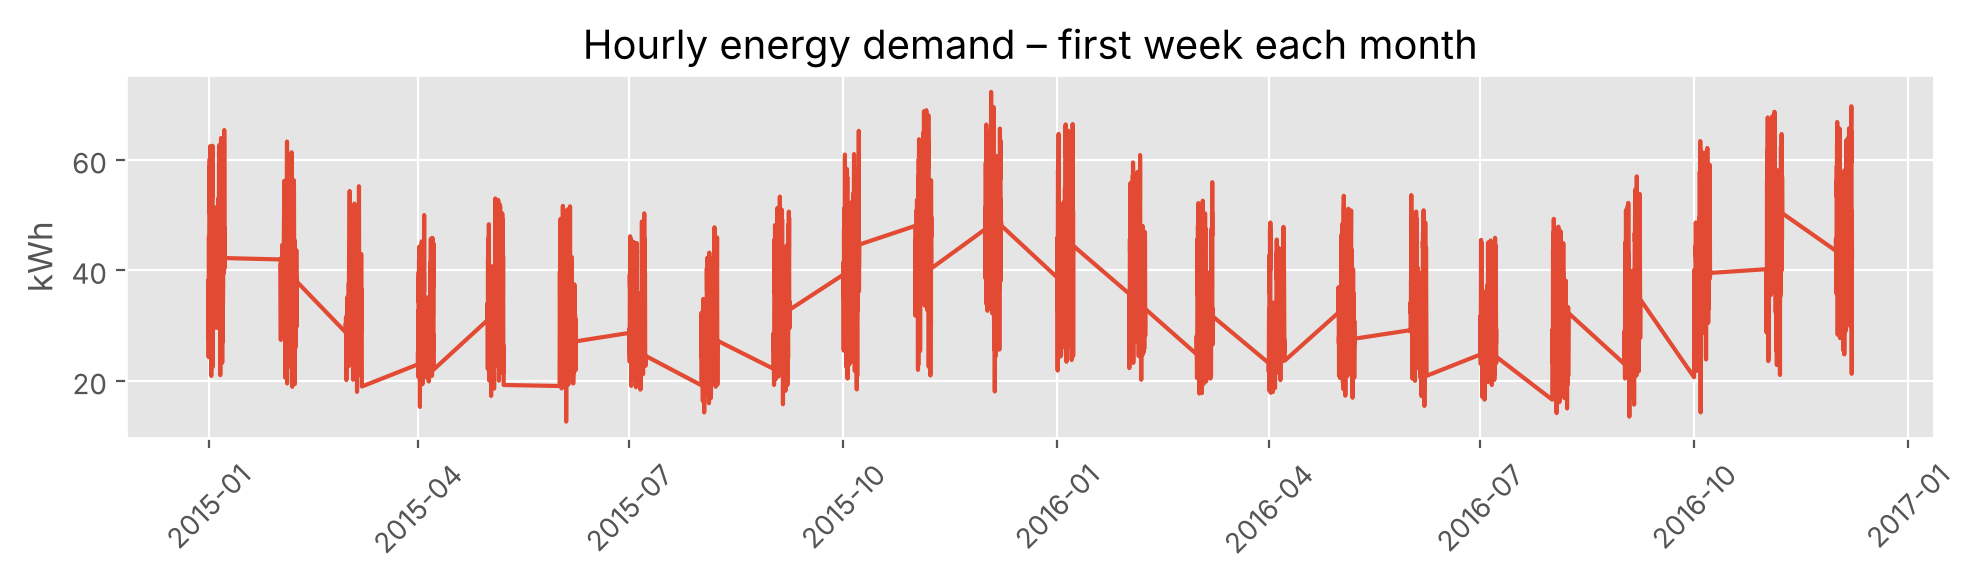

In [2]:
# -------- 2. Exploratory visualisations ------------------------------------

# 2‑A  Line‑plot glimpse: first 7 days of each month
sample = df[df["timestamp"].dt.day <= 7]
plt.figure(figsize=(10, 3))
plt.plot(sample["timestamp"], sample["energy_kwh"])
plt.ylabel("kWh")
plt.title("Hourly energy demand – first week each month")
plt.xticks(rotation=45)
plt.tight_layout()

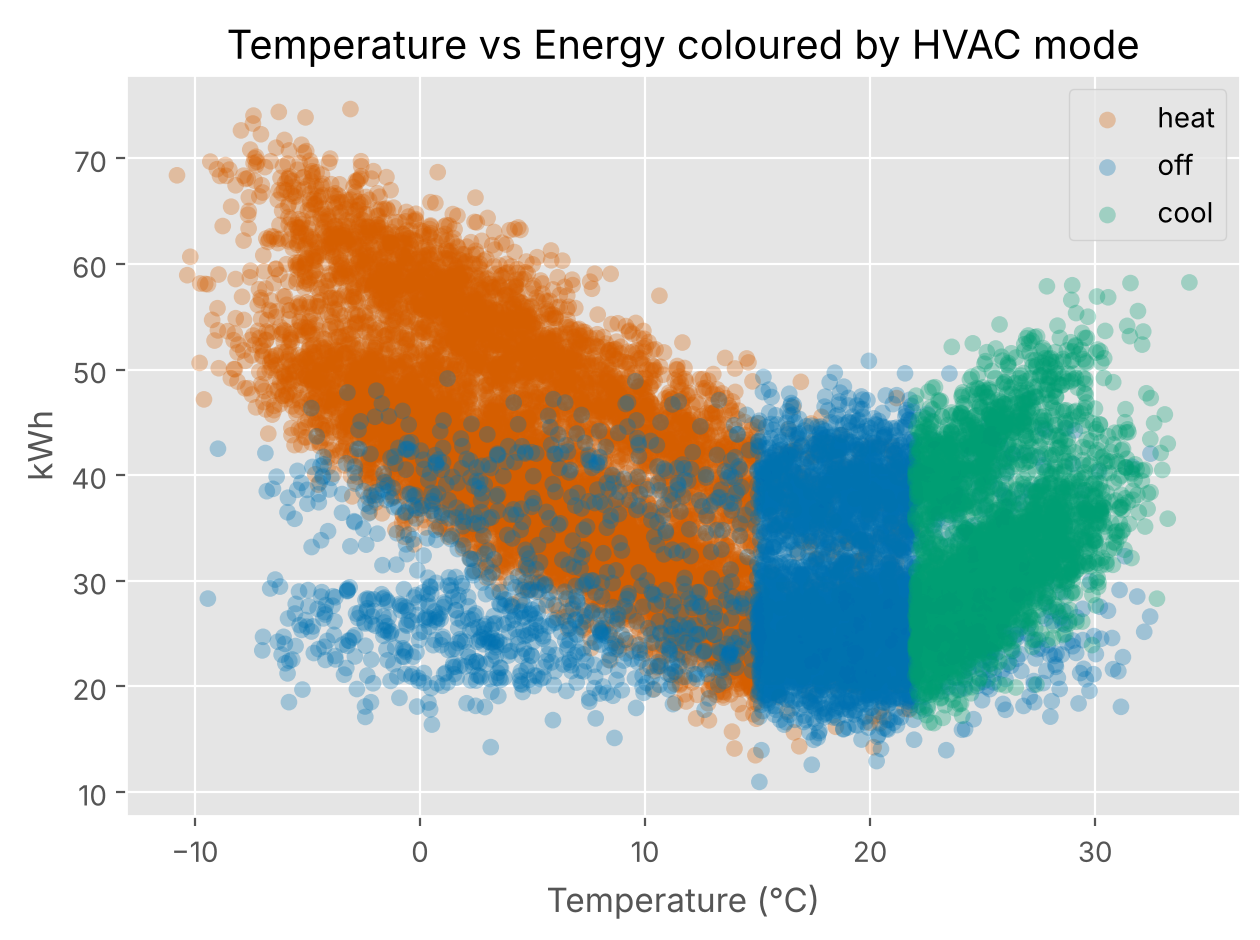

In [3]:
# 2‑B  Temperature vs Energy, coloured by HVAC mode
colour_map = {"heat": "#D55E00", "off": "#0072B2", "cool": "#009E73"}
plt.figure()
for mode, colour in colour_map.items():
    subset = df[df["hvac_mode"] == mode]
    plt.scatter(subset["temp_C"], subset["energy_kwh"],
                label=mode, c=colour, alpha=0.3, edgecolors="none")
plt.xlabel("Temperature (°C)")
plt.ylabel("kWh")
plt.title("Temperature vs Energy coloured by HVAC mode")
plt.legend()
plt.tight_layout()

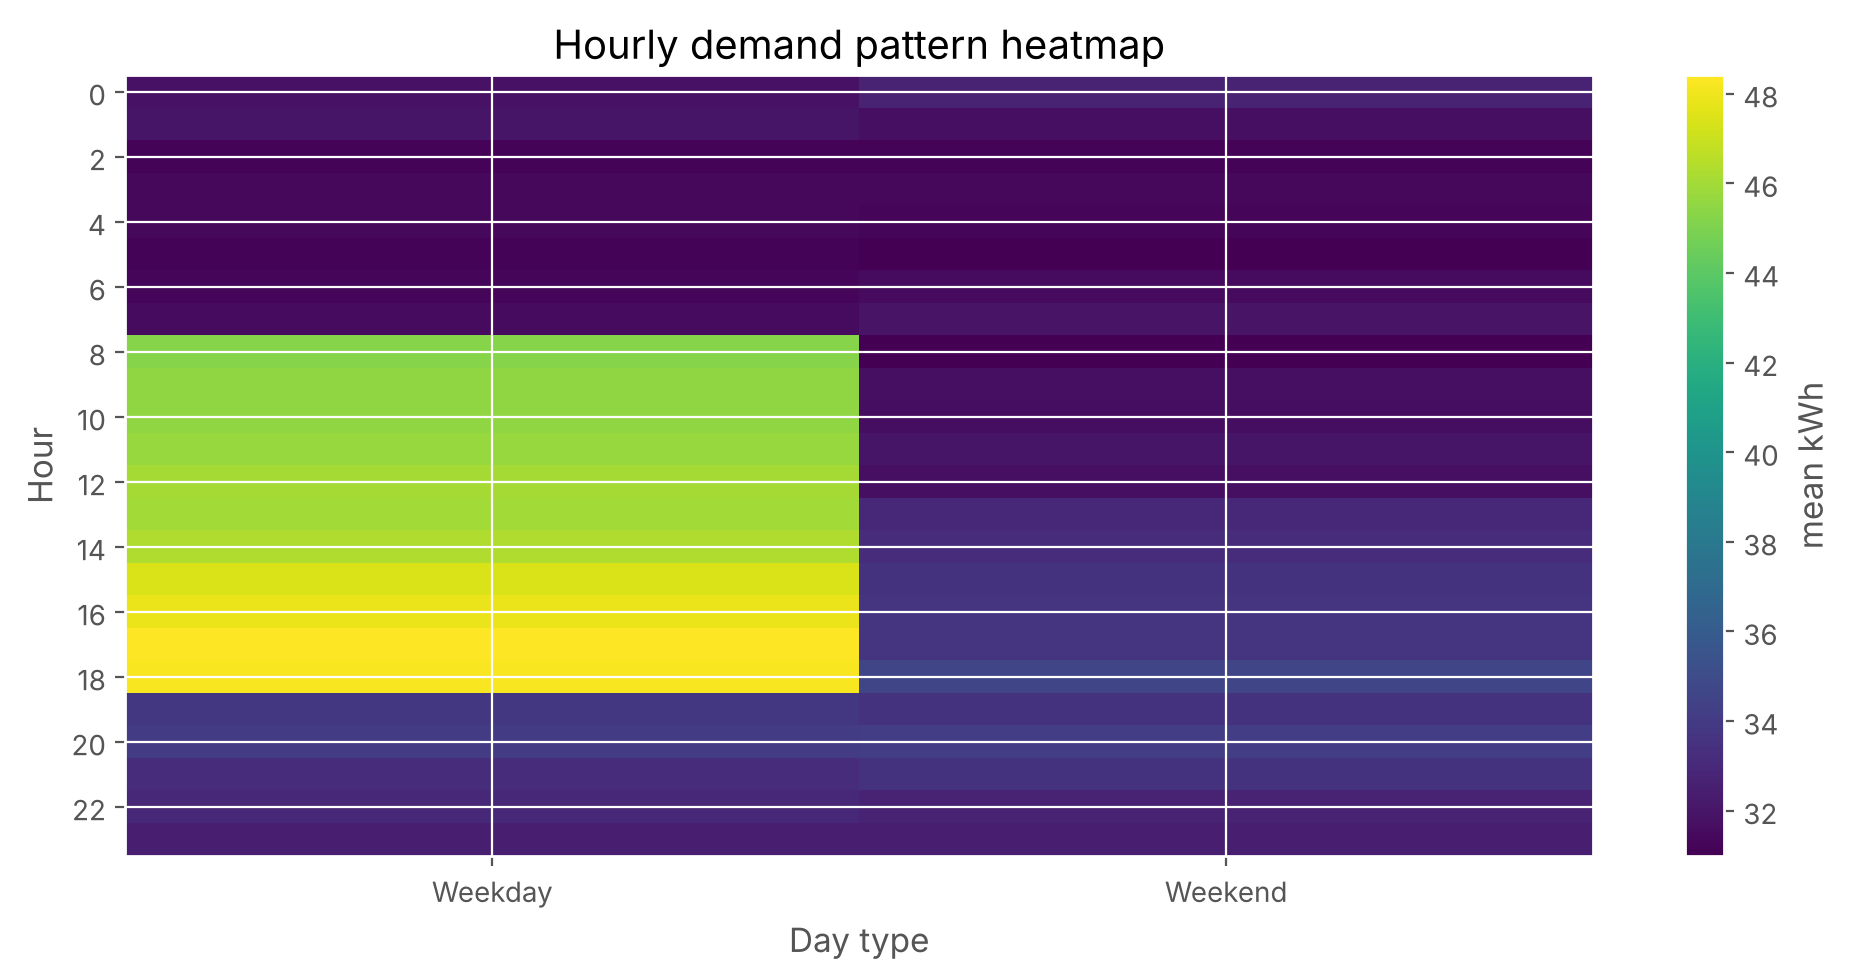

In [4]:
# 2‑C  Heatmap: mean kWh by hour vs weekday/weekend
pivot = df.pivot_table(index="hour_of_day",
                       columns="is_weekend",
                       values="energy_kwh",
                       aggfunc="mean")
plt.figure(figsize=(10, 5))
plt.imshow(pivot, aspect="auto")
plt.colorbar(label="mean kWh")
plt.xticks([0, 1.0], ["Weekday", "Weekend"])
plt.yticks(range(0, 24, 2))
plt.xlabel("Day type")
plt.ylabel("Hour")
plt.title("Hourly demand pattern heatmap")
plt.tight_layout()

In [5]:
# -------- 3. Time‑aware train/test split -----------------------------------
train = df[df["timestamp"].dt.year == 2015]
test  = df[df["timestamp"].dt.year == 2016]

X_train = train.drop(columns=["energy_kwh", "timestamp"])
y_train = train["energy_kwh"]
X_test  = test.drop(columns=["energy_kwh", "timestamp"])
y_test  = test["energy_kwh"]

In [6]:
# -------- 4. Preprocessing & model pipeline --------------------------------
numeric = ["temp_C", "humidity_pct", "occupants", "hour_of_day"]
categorical = ["hvac_mode", "is_weekend", "is_holiday"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(drop="first"), categorical)
])

poly = PolynomialFeatures(degree=2, include_bias=False)

model = Pipeline([
    ("prep", preprocess),
    ("poly", poly),
    ("linreg", LinearRegression())
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['temp_C','humidity_pct','occupants',...,'is_weekend','is_holiday', 'hvac_mode']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

In [7]:
# -------- 5. Evaluation ----------------------------------------------------
def metrics(name, y_true, y_pred):
    # Fixed: mean_squared_error returns MSE; RMSE is its square root
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"{name:>5}  RMSE = {rmse:6.2f} kWh   R² = {r2:6.3f}")

metrics("Train", y_train, model.predict(X_train))
metrics("Test ", y_test,  model.predict(X_test))


Train  RMSE =   3.07 kWh   R² =  0.920
Test   RMSE =   3.10 kWh   R² =  0.918


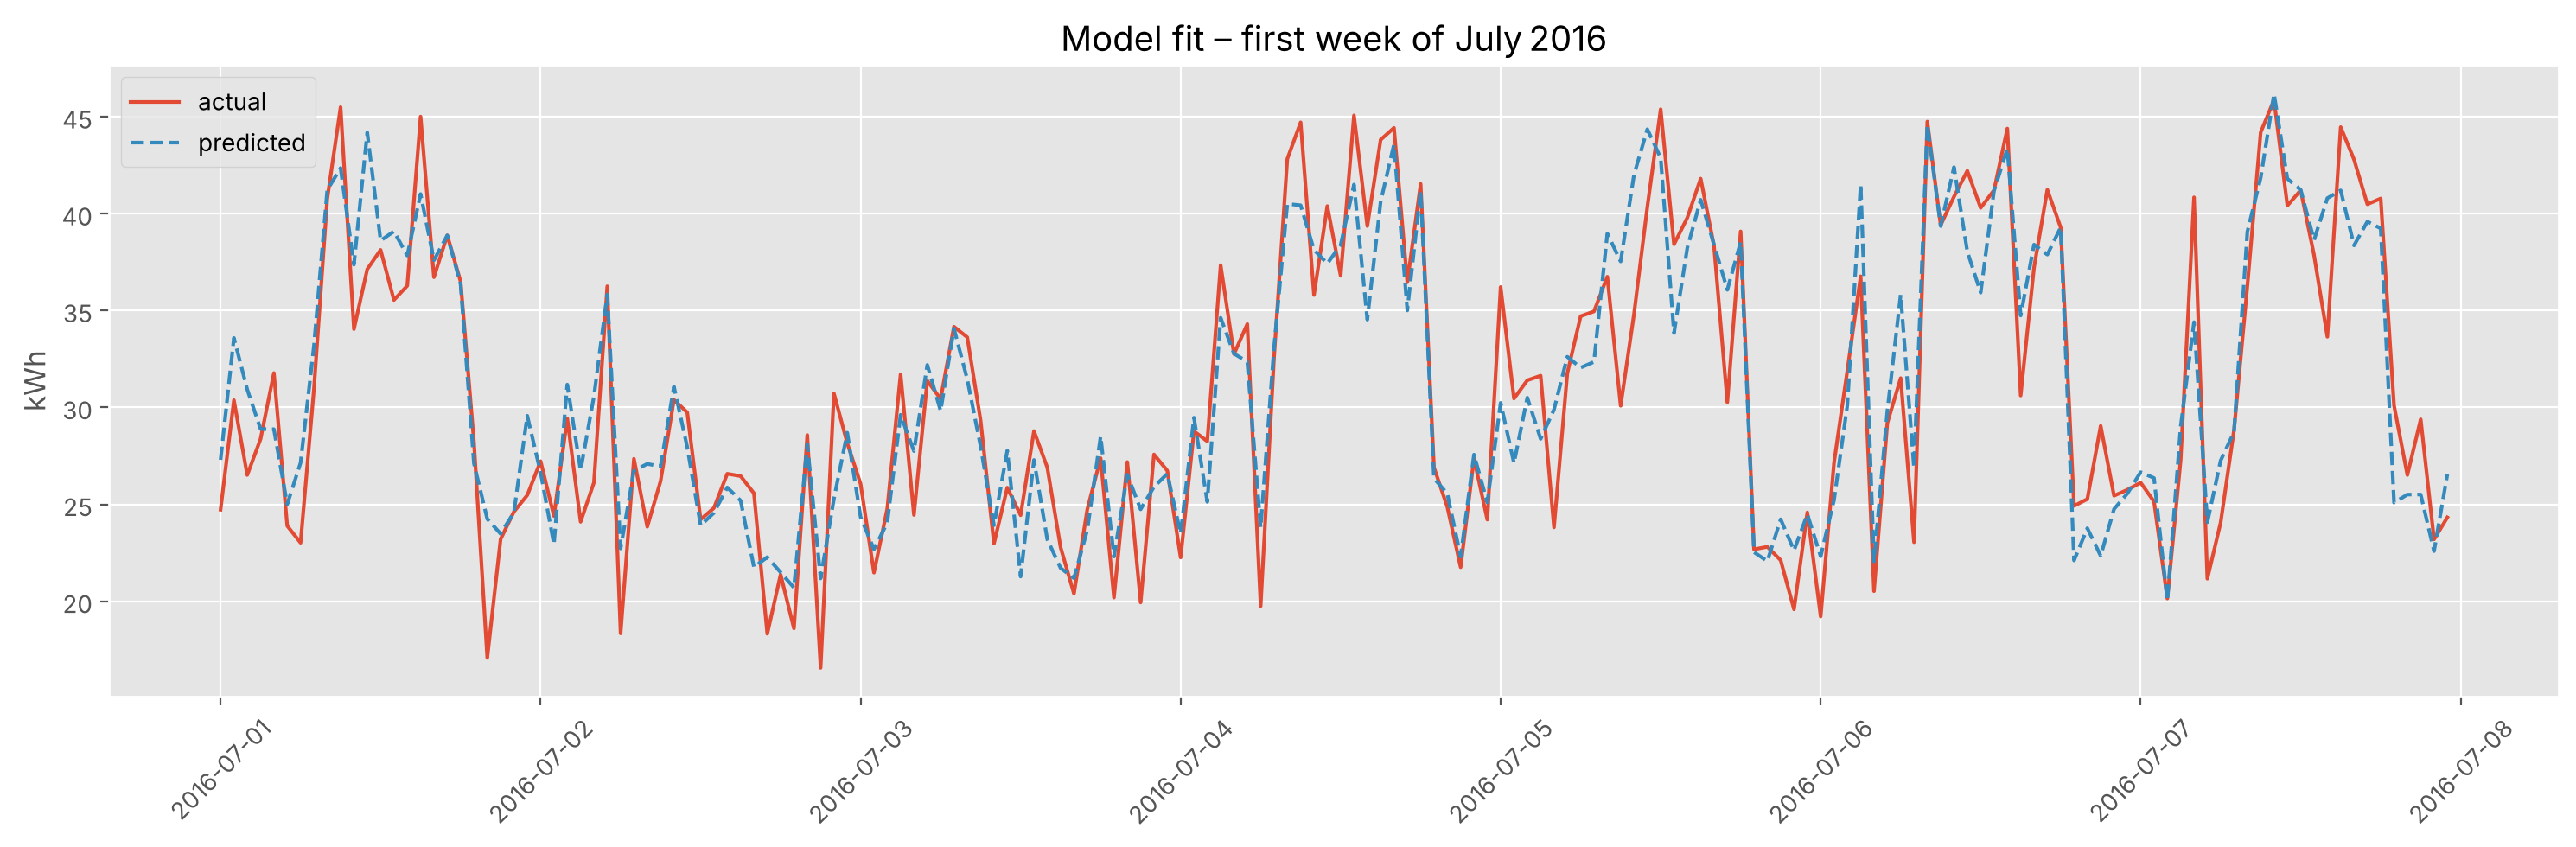

In [8]:
# -------- 6. Prediction‑vs‑actual plots ------------------------------------

# 6‑A  Line plot for a summer week
week_mask = (test["timestamp"] >= "2016-07-01") & (test["timestamp"] < "2016-07-08")
week = test.loc[week_mask]
week_pred = model.predict(week.drop(columns=["energy_kwh", "timestamp"]))

plt.figure(figsize=(15, 5))
plt.plot(week["timestamp"], week["energy_kwh"], label="actual")
plt.plot(week["timestamp"], week_pred, "--", label="predicted")
plt.ylabel("kWh")
plt.title("Model fit – first week of July 2016")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

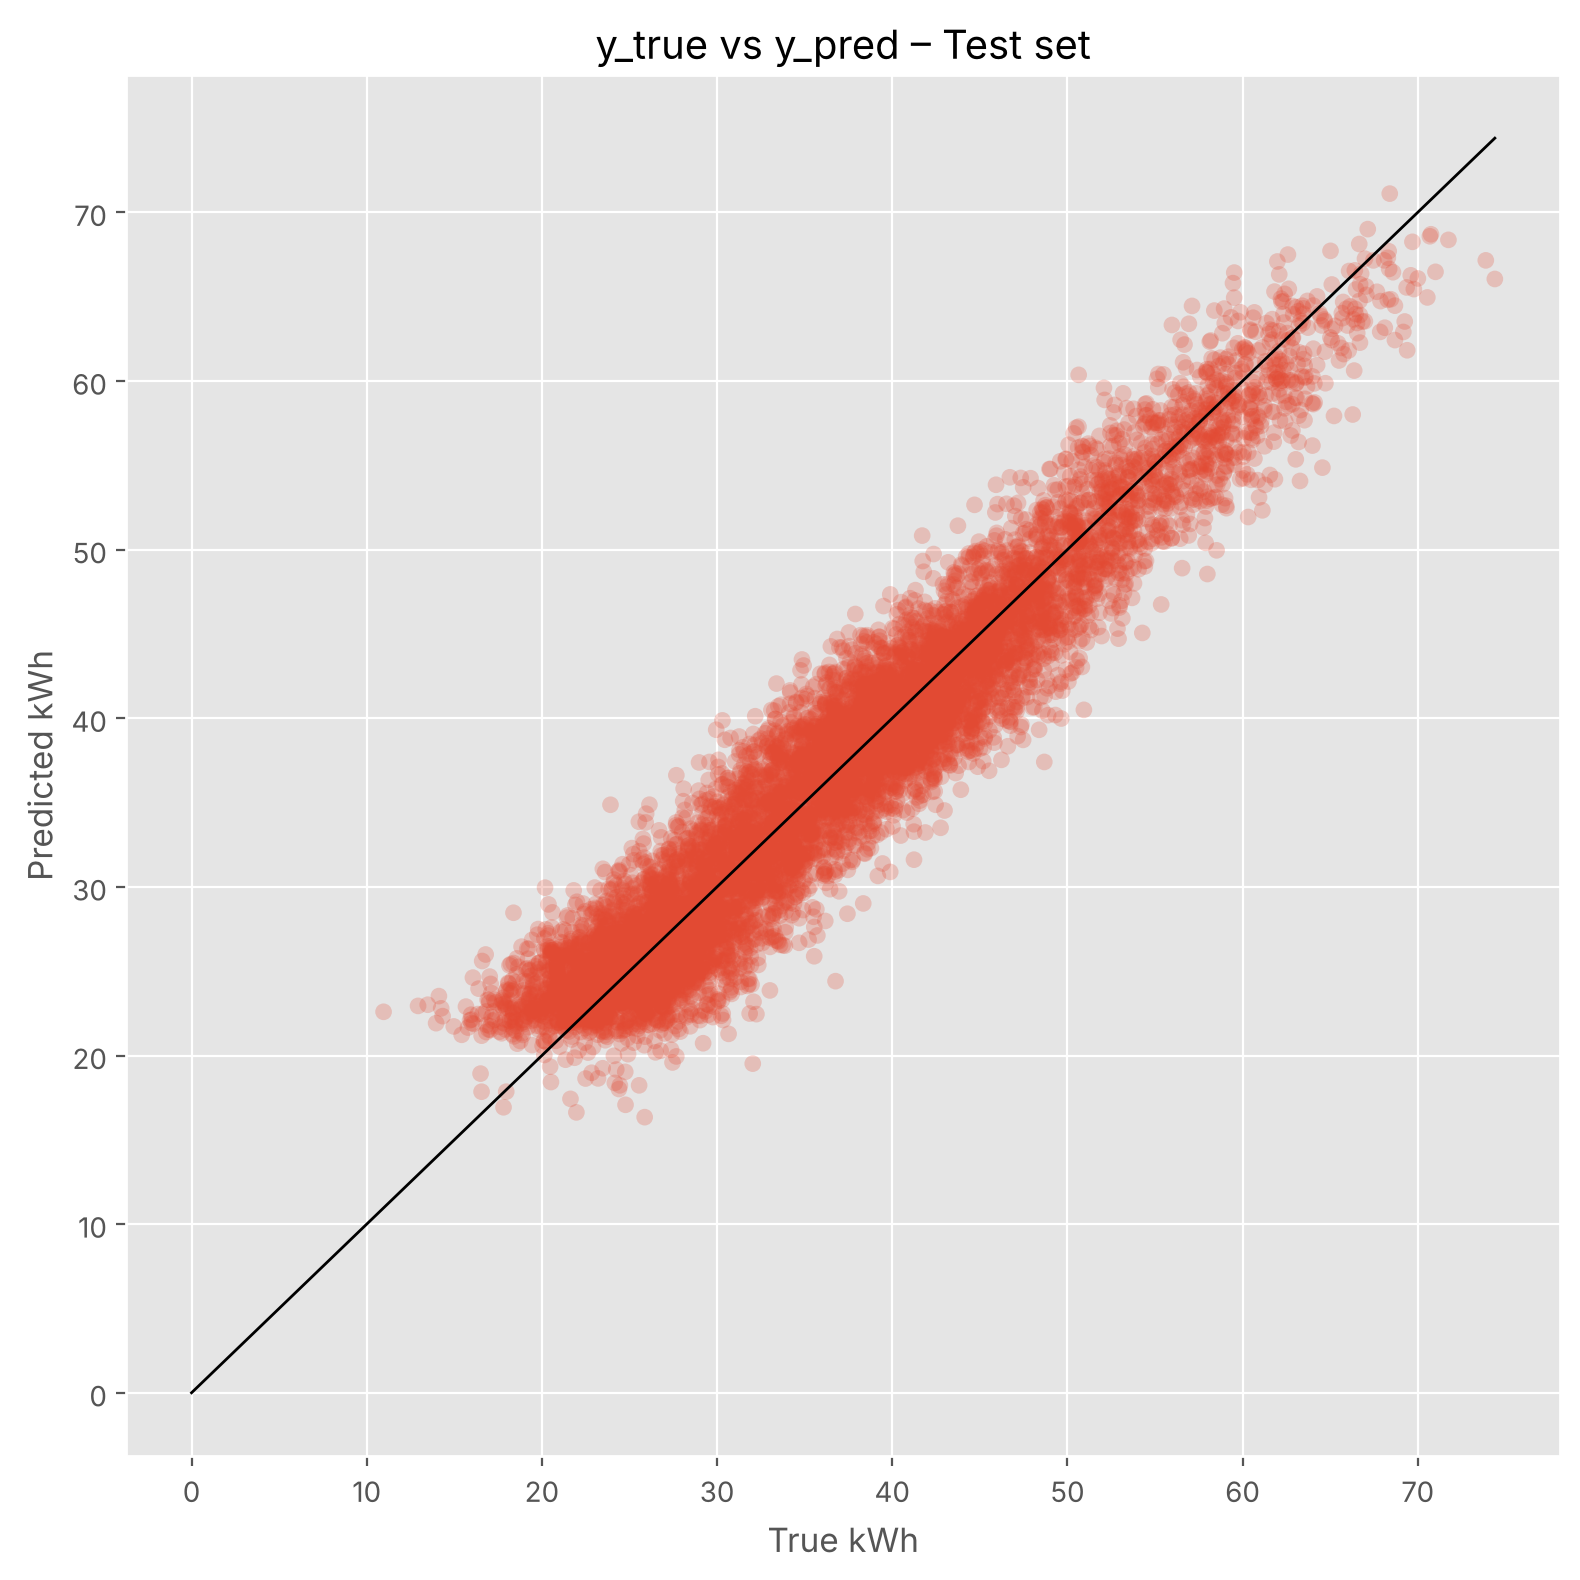

In [9]:
# 6‑B  Scatter y_true vs y_pred on full test set
y_pred_full = model.predict(X_test)
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_full, alpha=0.25, edgecolors="none")
max_val = max(y_test.max(), y_pred_full.max())
plt.plot([0, max_val], [0, max_val], color="black", linewidth=1)
plt.xlabel("True kWh")
plt.ylabel("Predicted kWh")
plt.title("y_true vs y_pred – Test set")
plt.tight_layout()

plt.show()
